# Nominal Rigidities and the Dynamic Effects of a Shock to Monetary Policy

Lawrence J. Christiano, Martin Eichenbaum, Charles L. Evans, *Journal of Political Economy* 113(1), 2005, pp. 1–45.

Replication by **Isabella Bonetto, Irene Ferraioli, Lorenzo Giordani, Alessio Morrone, Tiziano Nocco**.

**What this notebook replicates.** Section II of the paper: the VAR that identifies a monetary policy shock and the responses of nine U.S. aggregates to it, 1965Q3–1995Q3. These are the responses the paper's DSGE model is later estimated to match. The model itself (Sections III–VI) is not replicated here.

**Contents.**
1. The paper in brief
2. Identifying a monetary policy shock
3. Data
4. The reduced-form VAR
5. Recursive identification and impulse responses
6. Bootstrap confidence bands
7. How much of the fluctuations do policy shocks explain?
8. Comparison with the paper
9. Robustness: the price puzzle
10. Diagnostics and lag length

## 1. The paper in brief

CEE ask why inflation is **inertial** and why output responds **persistently** to monetary policy. They build a DSGE model with Calvo-staggered **prices and wages** (with indexation) and four real frictions: habit formation in consumption, investment adjustment costs, variable capital utilisation, and a working-capital requirement, so that firms borrow to pay wages.

They use a limited-information strategy in two steps:
1. Estimate the responses of U.S. aggregates to a monetary policy shock with an identified VAR (**this notebook**).
2. Choose the model's parameters $\gamma$ so that the model's impulse responses match the VAR's. With $\hat\Psi$ the stacked VAR responses and $\Psi(\gamma)$ the model's,
$$\hat\gamma = \arg\min_{\gamma}\; \big[\hat\Psi - \Psi(\gamma)\big]'\, V^{-1} \big[\hat\Psi - \Psi(\gamma)\big],$$
   where $V$ is diagonal and holds the sampling variances of the elements of $\hat\Psi$ (CEE, eq. 21). The model is pulled hardest toward the responses that are estimated precisely, i.e. it is asked to stay inside the VAR's confidence bands.

Main findings:
- **Moderate rigidities are enough.** In the estimated model prices are reoptimised about every **two quarters** and wages about every **three**. Yet the model reproduces the delayed, hump-shaped responses of output, consumption, investment, profits and productivity, and the weak response of the real wage.
- **Wage stickiness is the crucial nominal friction.** A version with sticky wages and flexible prices does almost as well as the full model. With sticky prices only, output persistence requires implausibly long price contracts.
- **The key is to keep marginal cost from jumping.** Firms set prices as a markup over marginal cost, whose main components are the wage and the rental rate of capital. After an expansionary shock, sticky wages hold back the first. **Variable capital utilisation** holds back the second: firms can supply more capital services by using existing capital more intensively, so the rental rate does not spike. Marginal cost rises slowly, so inflation rises slowly, and the rise in nominal spending turns into a persistent rise in real output.
- **Working capital** works in the same direction. Firms borrow to pay wages, so a lower interest rate directly lowers marginal cost. Without it, the estimated price contracts become much longer.
- **Habit formation and investment adjustment costs** matter little for inflation inertia, but they are needed for the hump-shaped paths of consumption and investment.
- **The real frictions matter for inference.** Without them, the estimated price and wage contracts become implausibly long.
- **Strong internal propagation.** The effects on output keep growing after most contracts in place at the time of the shock have been reoptimised, and they outlast the movements in the interest rate and in money growth.

## 2. Identifying a monetary policy shock

The Fed is assumed to set the federal funds rate according to

$$R_t = f(\Omega_t) + \varepsilon_t ,$$

where $f$ is linear, $\Omega_t$ is the Fed's information set, and $\varepsilon_t$, the **monetary policy shock**, is orthogonal to $\Omega_t$. The Fed lets money growth be whatever it takes for this rule to hold. The shock is therefore a surprise in the **interest rate**, not in the money supply, and money growth is an endogenous variable that can respond to it.

The variables are ordered as

$$Y_t = [\,Y_{1t},\; R_t,\; Y_{2t}\,]' .$$

| Block | Variables | Timing assumption |
|---|---|---|
| $Y_{1t}$ | real GDP, real consumption, GDP deflator, real investment, real wage, labour productivity | in $\Omega_t$; they **do not** respond to $\varepsilon_t$ within the quarter |
| $R_t$ | federal funds rate | the policy instrument |
| $Y_{2t}$ | real profits, growth rate of M2 | only their *past* values are in $\Omega_t$; they **may** respond within the quarter |

Placing most variables in $Y_{1t}$ reflects the long-standing view that many macroeconomic aggregates do not respond instantly to policy (Friedman, 1968). The assumption is debatable, but CEE impose the same timing in their model, so the VAR and the model are consistent with each other.

This timing is a set of zero restrictions on the impact of the shock. It identifies $\varepsilon_t$, and only $\varepsilon_t$. It does **not** require an ordering *within* $Y_{1t}$ or within $Y_{2t}$: the responses to the policy shock are the same for any order inside each block (CEE, 2005; Christiano, Eichenbaum and Evans, 1999). This is why a Cholesky factorisation, which does impose a full order, is harmless here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ---- settings ----
DATA_FILE = "data/NominalRigidities.xlsx"
SAMPLE = ("1965Q3", "1995Q3")      # estimation sample, as in the paper
P = 4                              # VAR lags
H = 20                             # IRF horizon, quarters
NREP = 2000                        # bootstrap replications
SEED = 1234
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 9.5, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.6,
})

## 3. Data

All series come from FRED and are stored in `data/NominalRigidities.xlsx` (sheets `Quarterly` and `Monthly`; the `README` sheet documents each series).

| VAR variable | FRED series | Construction |
|---|---|---|
| Real GDP | `GDPC1` | $100\log$ |
| Real consumption | `PCECC96` (real personal consumption expenditures) | $100\log$ |
| GDP deflator | `GDPDEF` (index) | $100\log$ |
| Real investment | `GPDIC1` | $100\log$ |
| Real wage | `COMPNFB` / `GDPDEF` (hourly compensation, nonfarm business) | $100\log$ |
| Labour productivity | `OPHNFB` (output per hour, nonfarm business) | $100\log$ |
| Federal funds rate | `FEDFUNDS`, quarterly average of monthly data | level, % per year |
| Real profits | `CPATAX` / `GDPDEF` (after-tax corporate profits with IVA and CCAdj) | $100\log$ |
| *Commodity prices (Section 9 only)* | `PPIACO` (PPI, all commodities), quarterly average | $100\log$ |
| M2 growth | `M2SL`, quarterly average of monthly data | $100\,\Delta\log$, % per quarter |

With $100\log$, every response reads directly as a **percent deviation**. All variables except the interest rate and money growth are in log levels, as in the paper; Section 4 discusses why a VAR in levels is fine.

*Vintage.* The data are today's FRED vintage (base year 2017), not the 2005 vintage CEE used, so the numbers cannot match the paper to the decimal. The shapes should.

In [2]:
q = pd.read_excel(DATA_FILE, sheet_name="Quarterly", index_col="observation_date")
m = pd.read_excel(DATA_FILE, sheet_name="Monthly", index_col="observation_date")
q.index = q.index.to_period("Q")
m_q = m.groupby(m.index.to_period("Q")).mean()      # quarterly averages of FEDFUNDS and M2
raw = q.join(m_q, how="inner")

ln = lambda s: 100 * np.log(s)
df = pd.DataFrame({
    "GDP":          ln(raw["GDPC1"]),
    "Consumption":  ln(raw["PCECC96"]),
    "Deflator":     ln(raw["GDPDEF"]),
    "Investment":   ln(raw["GPDIC1"]),
    "Real wage":    ln(raw["COMPNFB"] / raw["GDPDEF"]),
    "Productivity": ln(raw["OPHNFB"]),
    "Fed funds":    raw["FEDFUNDS"],
    "Real profits": ln(raw["CPATAX"] / raw["GDPDEF"]),
    "M2 growth":    ln(raw["M2SL"]).diff(),
})
VARS = list(df.columns)
MP = VARS.index("Fed funds")                 # position of the policy shock

# the estimation sample starts in 1965Q3; the P quarters before it are the initial lags
start, end = pd.Period(SAMPLE[0]), pd.Period(SAMPLE[1])
data = df.loc[start - P:end]
assert data.notna().all().all() and len(data) == (end - start).n + 1 + P
print(f"{len(data) - P} quarters, {data.index[P]}–{data.index[-1]}, plus {P} pre-sample quarters for the lags")
data.loc[start:].describe().T.round(2)[["mean", "std", "min", "max"]]

121 quarters, 1965Q3–1995Q3, plus 4 pre-sample quarters for the lags


,mean,std,min,max
GDP,889.80,26.62,841.53,934.58
Consumption,842.77,28.56,789.67,890.39
Deflator,358.66,46.28,280.91,420.62
Investment,683.04,31.27,630.94,738.49
Real wage,-48.29,11.91,-73.44,-29.72
Productivity,391.03,14.50,362.85,414.21
Fed funds,7.43,3.22,2.99,17.78
Real profits,146.10,24.28,94.37,208.34
M2 growth,1.74,0.97,-0.32,5.38


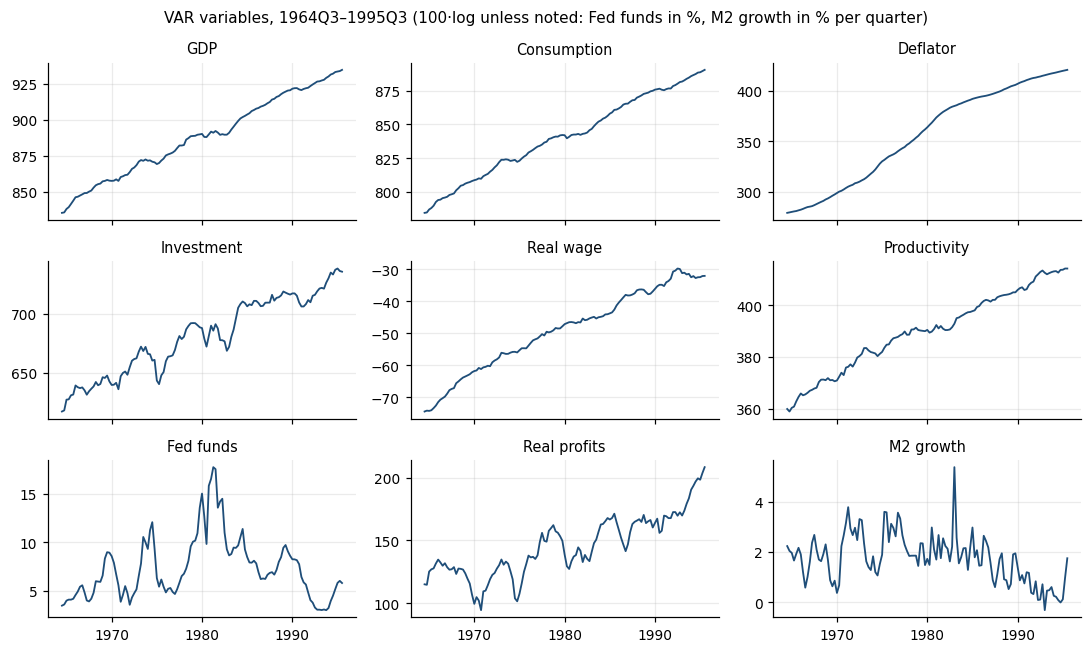

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(10, 6), sharex=True)
t = data.index.to_timestamp()
for ax, v in zip(axes.flat, VARS):
    ax.plot(t, data[v], color="#1f4e79", lw=1.2)
    ax.set_title(v)
    ax.xaxis.set_major_locator(mdates.YearLocator(10))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("VAR variables, 1964Q3–1995Q3 (100·log unless noted: Fed funds in %, M2 growth in % per quarter)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "data.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. The reduced-form VAR

### Structural and reduced form

The structural VAR is

$$A_0 Y_t = c^* + \sum_{i=1}^{p} A_i^* Y_{t-i} + \varepsilon_t, \qquad E[\varepsilon_t\varepsilon_t'] = \Sigma \text{ diagonal}.$$

Here $A_0$ holds the contemporaneous relations and the $\varepsilon_t$ are the structural shocks. We cannot estimate this directly: $Y_t$ appears on both sides through $A_0$. Premultiplying by $A_0^{-1}$ gives the **reduced form**

$$Y_t = c + \sum_{i=1}^{p} A_i Y_{t-i} + u_t, \qquad u_t = A_0^{-1}\varepsilon_t, \qquad \Omega \equiv E[u_tu_t'] = A_0^{-1}\Sigma A_0^{-1\prime}.$$

### Why identifying restrictions are needed

From the data we can recover $\Omega$, a symmetric matrix with $m(m+1)/2$ distinct elements. Normalise the diagonal of $A_0$ to one. The unknowns are then the $m(m-1)$ off-diagonal elements of $A_0$ and the $m$ variances in $\Sigma$: $m^2$ in total. We are short

$$m^2 - \frac{m(m+1)}{2} = \frac{m(m-1)}{2}$$

restrictions, which is 36 for $m = 9$. These must come from economics, not from the data. Section 5 supplies them.

### Estimation

We stack $X_t = [\,1,\;Y_{t-1}',\dots,Y_{t-p}'\,]$, so that the VAR reads $Y = XB + U$, with $B$ of size $(1+mp)\times m$ and $B' = [\,c,\;A_1,\dots,A_p\,]$. Each equation has the same regressors, so equation-by-equation OLS is efficient:

$$\hat B = (X'X)^{-1}X'Y, \qquad \hat\Omega = \frac{\hat U'\hat U}{T - (1+mp)} .$$

### Levels, unit roots and cointegration

Most of these series have a unit root, and the VAR is estimated in **levels**, as in the paper. Sims, Stock and Watson (1990) show that OLS on a VAR in levels still estimates the coefficients consistently, and that the estimates are consistent even if some variables are cointegrated. Differencing would impose unit roots and throw away the long-run relations among the levels.

Two caveats:
- In a cointegrated system the responses of the $I(1)$ **levels** need not return to zero. Only the stationary combinations do.
- IRFs at very long horizons are poorly estimated in a levels VAR (Phillips, 1998).

The second caveat is mild at the 20-quarter horizon used here. The first one matters for reading the results: the response of a level, such as the price level, can settle at a new value instead of returning to zero, and Section 9 shows exactly that. CEE report that imposing cointegrating relations instead (Altig et al., 2003) leaves the key properties of the responses unchanged.

### Companion form and stability

Stacking $\mathbf Y_t = [Y_t',\dots,Y_{t-p+1}']'$ turns the VAR($p$) into a VAR(1):

$$
\mathbf Y_t = \mathbf c + \mathbf A\,\mathbf Y_{t-1} + \mathbf U_t,\qquad
\mathbf A = \begin{bmatrix} A_1 & A_2 & \cdots & A_{p-1} & A_p\\ I_m & 0 & \cdots & 0 & 0\\ 0 & I_m & \cdots & 0 & 0\\ \vdots & & \ddots & & \vdots\\ 0 & 0 & \cdots & I_m & 0\end{bmatrix}.
$$

The VAR is stable when every eigenvalue of $\mathbf A$ is inside the unit circle. Its moving-average coefficients are then $\Phi_h = J\mathbf A^hJ'$, with $J = [\,I_m\;0\;\cdots\;0\,]$.

In [4]:
def lag_matrix(Y, p):
    # rows t = p..T-1: [1, Y_{t-1}, ..., Y_{t-p}]
    T = Y.shape[0]
    return np.hstack([np.ones((T - p, 1))] + [Y[p - i:T - i] for i in range(1, p + 1)])

def estimate_var(Y, p):
    X, Yt = lag_matrix(Y, p), Y[p:]
    B = np.linalg.lstsq(X, Yt, rcond=None)[0]           # (1 + mp) x m
    U = Yt - X @ B
    Omega = U.T @ U / (U.shape[0] - X.shape[1])         # degrees-of-freedom adjusted
    return B, U, Omega

def companion(B, m, p):
    A = np.zeros((m * p, m * p))
    A[:m] = B[1:].T                                     # [A_1 ... A_p]
    A[m:, :-m] = np.eye(m * (p - 1))
    return A

Y = data.values
m = Y.shape[1]
B, U, Omega = estimate_var(Y, P)
A = companion(B, m, P)
roots = np.abs(np.linalg.eigvals(A))
print(f"B: {B.shape}   residuals: {U.shape}   largest root modulus: {roots.max():.4f}")

B: (37, 9)   residuals: (121, 9)   largest root modulus: 0.9928


In [5]:
# cross-check the hand-written estimator against statsmodels
from statsmodels.tsa.api import VAR
sm_res = VAR(data.values).fit(P, trend="c")
print("max |B - B_statsmodels|         :", np.abs(B - sm_res.params).max())
print("max |Omega - Omega_statsmodels| :", np.abs(Omega - sm_res.sigma_u).max())

max |B - B_statsmodels|         : 0.0
max |Omega - Omega_statsmodels| : 0.0


## 5. Recursive identification and impulse responses

The Cholesky factorisation $\hat\Omega = CC'$, with $C$ lower triangular, gives one solution to the identification problem. It sets

$$A_0^{-1} = C, \qquad \Sigma = I_m, \qquad u_t = C\,\eta_t ,$$

so the structural shocks $\eta_t = C^{-1}u_t$ are orthogonal with unit variance. Because $C$ is lower triangular, the shock to variable $j$ moves only variables $j, j+1, \dots, m$ on impact. With the fed funds rate seventh, the **7th column of $C$** is the impact of a one-standard-deviation policy shock. Its zeros in rows 1–6 are exactly the restriction of Section 2: $Y_{1t}$ does not respond within the quarter.

The structural impulse responses follow from the moving-average form:

$$Y_t = \sum_{h=0}^{\infty}\Phi_h C\,\eta_{t-h}, \qquad \frac{\partial Y_{t+h}}{\partial \eta_{7,t}} = \Phi_h\,C\,e_7 .$$

On impact the shock reaches only the rate, profits and money. After that, it spreads to every variable through the lags, since $\Phi_h$ is full for $h \ge 1$.

As in the paper, we plot the response to an **expansionary** shock, a one-standard-deviation *fall* in the funds rate, over 20 quarters.

In [6]:
def irf(B, Omega, p, h, shock):
    # response of all variables to a one-s.d. structural shock, horizons 0..h: (m, h+1)
    m = Omega.shape[0]
    C = np.linalg.cholesky(Omega)
    A = companion(B, m, p)
    out = np.zeros((m, h + 1))
    state = np.zeros(m * p)
    state[:m] = C[:, shock]
    for k in range(h + 1):
        out[:, k] = state[:m]
        state = A @ state
    return out

C = np.linalg.cholesky(Omega)
impact = pd.Series(-C[:, MP], index=VARS)
print("Impact of an expansionary policy shock: column 7 of C, sign flipped")
impact.round(3) + 0.0

Impact of an expansionary policy shock: column 7 of C, sign flipped


GDP             0.000
Consumption     0.000
Deflator        0.000
Investment      0.000
Real wage       0.000
Productivity    0.000
Fed funds      -0.853
Real profits   -0.171
M2 growth       0.144
dtype: float64

## 6. Bootstrap confidence bands

We use a **residual bootstrap** (Runkle, 1987):
1. Resample the estimated residuals $\hat u_t$ with replacement, **whole rows at a time**, so that their cross-correlation is preserved. Before resampling, the residuals are rescaled by $\sqrt{T/(T-k)}$, with $k = 1 + mp = 37$ regressors per equation and $T = 121$. OLS residuals are smaller on average than the true errors, and with this many regressors the difference is large: their average square is $(T-k)/T \approx 0.69$ times $\hat\Omega$. Without the rescaling every artificial sample would have shocks about 17% smaller than the data, and the bands would be pulled towards zero (on impact, the point estimate of the funds-rate response would even lie outside its own 95% band).
2. Rebuild an artificial sample recursively from the estimated VAR, $Y_t^* = \hat c + \sum_i \hat A_i Y_{t-i}^* + u_t^*$, starting from the actual first $p$ observations.
3. Re-estimate the VAR on $Y^*$, re-identify it, and compute the IRFs.

Repeating this 2,000 times gives a distribution for each response. We plot the **95% percentile band** (2.5th–97.5th percentiles) and a 68% band inside it.

Two caveats. CEE compute their 95% bands with the method of Sims and Zha (1999), so our bands are comparable in spirit but not identical. And resampling rows treats the residuals as serially independent; Section 10 shows that this is not fully true for the VAR(4), so the bands are, if anything, somewhat too narrow.

In [7]:
def bootstrap_irf(Y, p, h, shock, nrep, seed):
    rng = np.random.default_rng(seed)
    B, U, _ = estimate_var(Y, p)
    U = U * np.sqrt(U.shape[0] / (U.shape[0] - B.shape[0]))   # residuals with the variance of the errors
    T, m = Y.shape
    c, A_lags = B[0], B[1:]
    draws = np.empty((nrep, m, h + 1))
    for r in range(nrep):
        Ub = U[rng.integers(0, U.shape[0], U.shape[0])]
        Yb = np.empty_like(Y)
        Yb[:p] = Y[:p]
        for t in range(p, T):                              # every row is rebuilt: t = p .. T-1
            lags = Yb[t - p:t][::-1].ravel()               # [Y_{t-1}, ..., Y_{t-p}]
            Yb[t] = c + lags @ A_lags + Ub[t - p]
        Bb, _, Ob = estimate_var(Yb, p)
        draws[r] = irf(Bb, Ob, p, h, shock)
    return draws

point = -irf(B, Omega, P, H, MP)                           # expansionary: sign flipped
draws = -bootstrap_irf(Y, P, H, MP, NREP, SEED)
lo95, lo68, hi68, hi95 = np.percentile(draws, [2.5, 16, 84, 97.5], axis=0)
print(f"{NREP} replications done")

2000 replications done


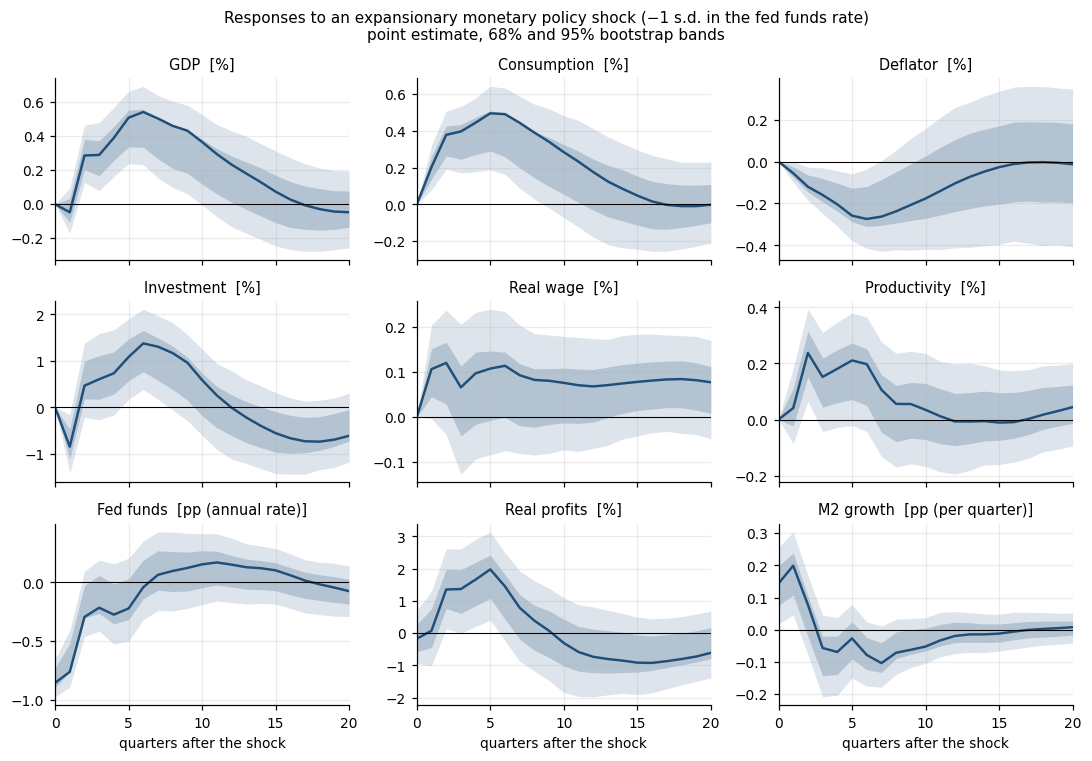

In [8]:
UNITS = ["%"] * 6 + ["pp (annual rate)", "%", "pp (per quarter)"]
q_ = np.arange(H + 1)

fig, axes = plt.subplots(3, 3, figsize=(10, 7), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.fill_between(q_, lo95[i], hi95[i], color="#1f4e79", alpha=0.15, lw=0)
    ax.fill_between(q_, lo68[i], hi68[i], color="#1f4e79", alpha=0.22, lw=0)
    ax.plot(q_, point[i], color="#1f4e79")
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(f"{VARS[i]}  [{UNITS[i]}]")
    ax.set_xlim(0, H)
for ax in axes[-1]:
    ax.set_xlabel("quarters after the shock")
fig.suptitle("Responses to an expansionary monetary policy shock (−1 s.d. in the fed funds rate)\n"
             "point estimate, 68% and 95% bootstrap bands", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "irf_monetary_shock.png", dpi=150, bbox_inches="tight")
plt.show()

### Price level or inflation?

The VAR contains the *level* of the deflator, while the paper discusses **inflation**. The two carry the same information: if $p_h$ is the response of $100\log P$ at horizon $h$, the response of annualised quarterly inflation is

$$\pi_h = 4\,(p_h - p_{h-1}), \qquad p_{-1} = 0 .$$

We compute it for the point estimate and for every bootstrap draw, so it gets its own bands.

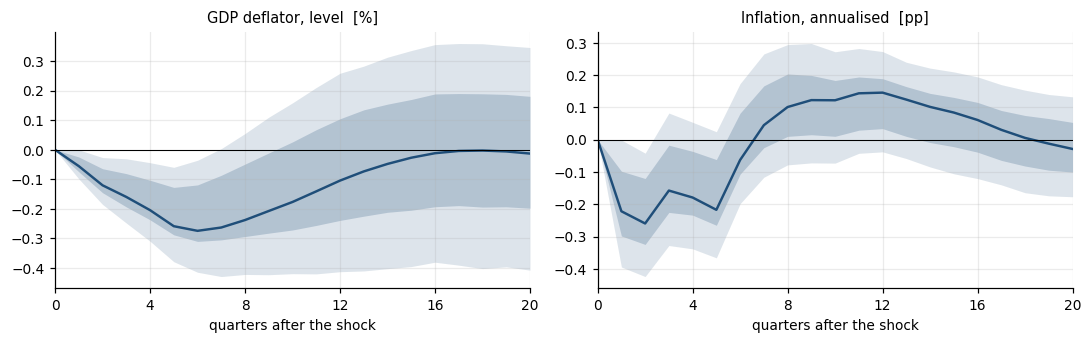

,"inflation (pp, annual)",95% low,95% high
quarter,,,
1,-0.22,-0.39,0.00
2,-0.26,-0.42,-0.04
4,-0.18,-0.34,0.05
6,-0.06,-0.20,0.17
8,0.10,-0.08,0.29
10,0.12,-0.07,0.27
12,0.15,-0.04,0.27
16,0.06,-0.12,0.19
20,-0.03,-0.18,0.13


In [9]:
D = VARS.index("Deflator")
infl = lambda lvl: 4 * np.diff(lvl, prepend=0.0, axis=-1)     # pp at an annual rate
infl_point = infl(point[D])
infl_draws = infl(draws[:, D, :])
ilo95, ilo68, ihi68, ihi95 = np.percentile(infl_draws, [2.5, 16, 84, 97.5], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
panels = [("GDP deflator, level  [%]", point[D], lo95[D], lo68[D], hi68[D], hi95[D]),
          ("Inflation, annualised  [pp]", infl_point, ilo95, ilo68, ihi68, ihi95)]
for ax, (title, pt, a, b, c, d) in zip(axes, panels):
    ax.fill_between(q_, a, d, color="#1f4e79", alpha=0.15, lw=0)
    ax.fill_between(q_, b, c, color="#1f4e79", alpha=0.22, lw=0)
    ax.plot(q_, pt, color="#1f4e79")
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(title); ax.set_xlim(0, H); ax.set_xticks(range(0, H + 1, 4)); ax.set_xlabel("quarters after the shock")
fig.tight_layout()
fig.savefig(FIG / "deflator_inflation.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"inflation (pp, annual)": infl_point, "95% low": ilo95, "95% high": ihi95},
             index=pd.Index(q_, name="quarter")).iloc[[1, 2, 4, 6, 8, 10, 12, 16, 20]].round(2) + 0.0

In [10]:
# peak responses, for the discussion below
peaks = pd.DataFrame({
    "impact": point[:, 0],
    "peak": [point[i, np.argmax(np.abs(point[i]))] for i in range(m)],
    "peak quarter": [int(np.argmax(np.abs(point[i]))) for i in range(m)],
    "95% band excludes 0 at peak": [bool(lo95[i, k] > 0 or hi95[i, k] < 0)
                                    for i, k in enumerate(np.argmax(np.abs(point), axis=1))],
}, index=VARS)
peaks[["impact", "peak"]] = peaks[["impact", "peak"]].round(3) + 0.0     # + 0.0 turns -0.0 into 0.0
peaks

,impact,peak,peak quarter,95% band excludes 0 at peak
GDP,0.000,0.542,6,True
Consumption,0.000,0.495,5,True
Deflator,0.000,-0.274,6,True
Investment,0.000,1.374,6,True
Real wage,0.000,0.120,2,False
Productivity,0.000,0.238,2,True
Fed funds,-0.853,-0.853,0,True
Real profits,-0.171,1.978,5,True
M2 growth,0.144,0.199,1,True


### Reading the responses

**The shock.** The funds rate falls by about 85 basis points on impact. It is back to baseline after about six quarters and then slightly overshoots. The shock is short-lived; the effects that follow are not.

**Real activity (hump-shaped and persistent).** GDP does not move on impact, by assumption, and then rises in a hump: it peaks at about **+0.54%** after **six quarters**, when the funds rate has already returned to baseline, and fades out over roughly four years. Consumption (peak +0.50%, quarter 5) and investment (peak +1.37%, quarter 6) follow the same pattern. Investment moves about 2.5 times as much as GDP. This is the persistence that CEE's model has to reproduce: the effects on activity outlast the policy move itself. Before the hump, investment falls by about 0.85% in the first quarter, and this fall is significant at the 95% level; Section 8 comes back to it.

**Profits, productivity and wages.** Real profits rise strongly, to about +2% after five quarters. Labour productivity rises early, which is consistent with firms using existing capital and labour more intensively (the variable-utilisation channel in the model). The real wage rises only slightly (about +0.1%), and its 95% band includes zero at every horizon.

**Money.** M2 growth rises on impact and for a quarter, so the fall in the rate is accompanied by a monetary expansion, and then turns slightly negative.

**Prices (the main difference from the paper).** The GDP deflator *falls* for about six quarters, by up to 0.27%, and the fall is significant at the 95% level for the first six quarters. It returns to baseline only after about four years. In terms of inflation (the figure above) the picture is clearer. Inflation dips by about a quarter of a point in the first year and a half; that dip is outside the 95% band only in the first two quarters. It then turns **positive from the seventh quarter**, peaks at about **+0.15 points after three years**, and fades out after four and a half. The delayed, gradual rise is the inertia CEE document, although here it is significant only at the 68% level. The initial dip, with the wrong sign, is the well-known **price puzzle**. CEE's own inflation response also dips in the first quarter, but by about half as much and inside their bands (Section 8). The puzzle is sensitive to the specification: the usual remedy is to add a commodity-price index to the Fed's information set (Sims, 1992; Christiano, Eichenbaum and Evans, 1999), which we do in Section 9. The data vintage also differs from the paper's.

## 7. How much of the fluctuations do policy shocks explain?

The third question of Section II. The share of the $h$-step forecast error variance of variable $i$ due to the policy shock is

$$\mathrm{FEVD}_{i}(h) = \frac{\sum_{k=0}^{h-1}\big(\Phi_k C\big)_{i,7}^2}{\sum_{k=0}^{h-1}\sum_{j=1}^{m}\big(\Phi_k C\big)_{i,j}^2}.$$

Because the shocks are orthogonal, the shares across the $m$ shocks add up to one. The policy shock's share does not depend on how the variables are ordered within $Y_{1t}$ or within $Y_{2t}$.

In [11]:
def fevd_share(B, Omega, p, horizons, shock):
    m = Omega.shape[0]
    resp = np.stack([irf(B, Omega, p, max(horizons), j) for j in range(m)])   # (shock, var, h)
    sq = np.cumsum(resp ** 2, axis=2)
    return pd.DataFrame({f"h = {h}": 100 * sq[shock, :, h - 1] / sq[:, :, h - 1].sum(0) for h in horizons},
                        index=VARS)

fevd = fevd_share(B, Omega, P, [1, 4, 8, 12, 20], MP)
print("Share of the forecast error variance due to the monetary policy shock (%)")
fevd.round(1)

Share of the forecast error variance due to the monetary policy shock (%)


,h = 1,h = 4,h = 8,h = 12,h = 20
GDP,0.0,11.4,36.5,34.2,22.9
Consumption,0.0,23.8,34.7,27.6,19.7
Deflator,0.0,7.5,12.5,7.7,3.1
Investment,0.0,4.2,13.2,13.6,13.3
Real wage,0.0,2.6,4.2,5.1,6.7
Productivity,0.0,5.8,7.7,5.9,4.8
Fed funds,78.6,38.2,23.1,18.6,16.9
Real profits,0.2,5.3,11.4,8.6,9.8
M2 growth,5.7,11.3,13.2,14.0,12.7


The policy shock accounts for little of the forecast error variance at short horizons for the variables in $Y_{1t}$ (zero on impact, by construction). At two to three years it explains about a third of the variance of GDP and consumption, and about 13% of that of investment. Its share in the variance of the deflator stays small, at most about 12%. The funds rate itself is mostly driven by the policy shock on impact (79%). Most of its later movements are the *systematic* response to the other shocks: the policy rule, rather than policy surprises.

## 8. Comparison with the paper

The paper reports its VAR responses only as a figure (Figure 1) and its variance decompositions in Table 1. The figure values below are **read off the plot by eye**, so they are approximate to about one grid step; the table values are exact. In Figure 1 the shock hits in period 3, so a point plotted at period $x$ is horizon $h = x - 3$ here.

Units follow the paper: percent for the levels, annualised percentage points for inflation and the funds rate. The paper's caption puts money growth in annualised points too, so we multiply our quarterly M2 growth by 4.

In [12]:
# CEE (2005), Figure 1, VAR point estimates read off the plot: (value, horizon in quarters)
PAPER_FIG1 = {
    "GDP, peak":                 (0.50, 5),
    "Consumption, peak":         (0.20, 4),
    "Investment, peak":          (1.00, 5),
    "Real wage, peak":           (0.08, 4),
    "Productivity, peak":        (0.25, 3),
    "Real profits, peak":        (2.20, 4),
    "Inflation, first-year dip": (-0.12, 1),
    "Inflation, peak":           (0.20, 9),
    "Fed funds, impact":         (-0.65, 0),
    "M2 growth (annualised), peak": (0.20, 1),
}

def peak(x, sign=1, upto=None):
    x = np.asarray(x)[:upto]
    k = int(np.argmax(sign * x))
    return x[k], k

ours = {
    "GDP, peak":                 peak(point[VARS.index("GDP")]),
    "Consumption, peak":         peak(point[VARS.index("Consumption")]),
    "Investment, peak":          peak(point[VARS.index("Investment")]),
    "Real wage, peak":           peak(point[VARS.index("Real wage")]),
    "Productivity, peak":        peak(point[VARS.index("Productivity")]),
    "Real profits, peak":        peak(point[VARS.index("Real profits")]),
    "Inflation, first-year dip": peak(infl_point, sign=-1, upto=5),
    "Inflation, peak":           peak(infl_point),
    "Fed funds, impact":         (point[MP, 0], 0),
    "M2 growth (annualised), peak": peak(4 * point[VARS.index("M2 growth")]),
}

comparison = pd.DataFrame({
    "CEE value":   {k: v[0] for k, v in PAPER_FIG1.items()},
    "ours":        {k: v[0] for k, v in ours.items()},
    "CEE quarter": {k: v[1] for k, v in PAPER_FIG1.items()},
    "our quarter": {k: v[1] for k, v in ours.items()},
})
comparison[["CEE value", "ours"]] = comparison[["CEE value", "ours"]].round(2) + 0.0
comparison

,CEE value,ours,CEE quarter,our quarter
"GDP, peak",0.50,0.54,5,6
"Consumption, peak",0.20,0.50,4,5
"Investment, peak",1.00,1.37,5,6
"Real wage, peak",0.08,0.12,4,2
"Productivity, peak",0.25,0.24,3,2
"Real profits, peak",2.20,1.98,4,5
"Inflation, first-year dip",-0.12,-0.26,1,2
"Inflation, peak",0.20,0.15,9,12
"Fed funds, impact",-0.65,-0.85,0,0
"M2 growth (annualised), peak",0.20,0.80,1,1


In [13]:
# CEE (2005), Table 1: % of the k-step forecast error variance due to the policy shock
PAPER_TAB1 = pd.DataFrame(
    [[15, 38, 27], [1, 4, 7], [14, 21, 14], [10, 26, 23], [2, 2, 4],
     [15, 14, 10], [32, 19, 18], [19, 19, 19], [13, 18, 7]],
    index=["GDP", "Inflation", "Consumption", "Investment", "Real wage",
           "Productivity", "Fed funds", "M2 growth", "Real profits"],
    columns=[4, 8, 20])

# inflation is not in the VAR: its MA coefficients are the first differences of the deflator's
resp_all = np.stack([irf(B, Omega, P, 20, j) for j in range(m)])            # (shock, var, h)
d_resp = np.diff(resp_all[:, D, :], prepend=0.0, axis=-1)                   # (shock, h)
sq_infl = np.cumsum(d_resp ** 2, axis=1)
fevd_infl = {k: 100 * sq_infl[MP, k - 1] / sq_infl[:, k - 1].sum() for k in [4, 8, 20]}

ours_tab = fevd[["h = 4", "h = 8", "h = 20"]].set_axis([4, 8, 20], axis=1)
ours_tab.loc["Inflation"] = fevd_infl
ours_tab = ours_tab.loc[PAPER_TAB1.index]

pd.concat({"CEE, Table 1": PAPER_TAB1, "ours": ours_tab.round(0)}, axis=1).astype(int)

CEE, Table 1         ours        
                       4   8   20   4   8   20
GDP                    15  38  27   11  36  23
Inflation               1   4   7    9  10   9
Consumption            14  21  14   24  35  20
Investment             10  26  23    4  13  13
Real wage               2   2   4    3   4   7
Productivity           15  14  10    6   8   5
Fed funds              32  19  18   38  23  17
M2 growth              19  19  19   11  13  13
Real profits           13  18   7    5  11  10

**Impulse responses.** The qualitative picture is the paper's, item by item: real activity rises in a hump that peaks after about a year and a half, inflation rises with a delay of about two years, the funds rate falls for roughly a year, profits, productivity and the real wage rise, and money growth jumps immediately (CEE's points 1–5 in Section II).

- **GDP, productivity, profits, real wage.** Close to the paper in size and timing: GDP peaks at +0.54% after six quarters against CEE's +0.5% after five.
- **The shock is larger.** Our funds rate falls by 85 basis points on impact against about 65. Per point of rate cut, our GDP response (0.54/0.85 ≈ 0.64) is in fact somewhat *smaller* than CEE's (0.5/0.65 ≈ 0.77).
- **Consumption and investment are larger.** Consumption peaks at +0.50% against +0.2%, the largest quantitative difference; investment at +1.37% against +1.0%. Investment also *falls* by about 0.85% in the first quarter, outside the 95% band, before rising; CEE's investment shows no such dip. Both are most likely due to the data: today's chain-weighted NIPA series (base 2017) differ from the fixed-weight vintage CEE used precisely in how consumption and investment are deflated.
- **Inflation.** The peak is similar in size (+0.15 against +0.2 points) but comes three quarters later, and the initial dip is twice as deep (−0.26 against −0.12). Section 9 shows that most of this gap is the price puzzle.
- **Money growth.** In annualised points our peak is four times CEE's (0.8 against 0.2); in points per quarter it is exactly theirs (0.2). Most likely the caption's "APR" does not apply to money growth, and CEE's series is not annualised.

**Variance decomposition.** The orders of magnitude agree, and so does the main message: the policy shock explains a nontrivial share of real activity and very little of inflation. Output is close at every horizon (11, 36, 23% against 15, 38, 27%), and so is the funds rate. Consumption gets a larger share in our VAR, and investment, productivity, money growth and profits smaller ones. Our inflation share is higher at short horizons (9% against 1% at four quarters), again because of the early dip. CEE themselves warn that the decompositions are much less robust than the impulse responses and that their 95% intervals are wide (Table 1 and p. 9); all our shares lie inside CEE's 95% intervals except inflation at four quarters.

## 9. Robustness: the price puzzle

Why would prices fall after a monetary *expansion*? The standard explanation (Sims, 1992) is about what the Fed knows. Suppose the Fed cuts rates when it sees signs of lower future inflation that the VAR does not contain. The VAR then attributes the disinflation that was coming anyway to the policy shock.

Commodity prices are a timely signal of future inflation. Christiano, Eichenbaum and Evans (1999) add them to the Fed's information set $Y_{1t}$. We do the same: the index enters just before the funds rate, and everything else is unchanged. Only the ordering between $Y_{1t}$ and $R_t$ matters for the policy shock, so its exact position inside $Y_{1t}$ is irrelevant.

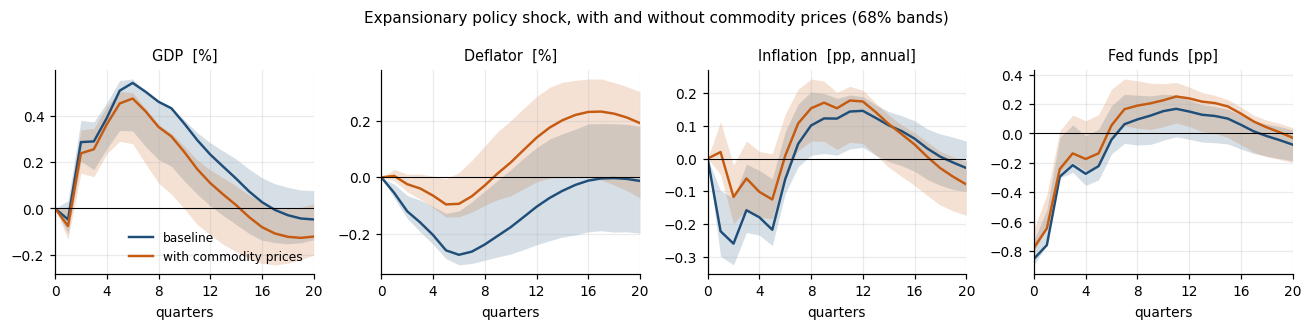

,baseline,with commodity prices
GDP peak (%),0.54,0.47
GDP peak quarter,6.00,6.00
deflator trough (%),-0.27,-0.10
quarters deflator < 0 at 95%,6.00,0.00
inflation trough (pp),-0.26,-0.12
inflation > 0 from quarter (to q12),7.00,6.00
deflator at q12 (%),-0.10,0.14
fed funds impact (pp),-0.85,-0.78


In [14]:
df_c = df.copy()
df_c.insert(VARS.index("Fed funds"), "Commodity prices", ln(raw["PPIACO"]))
VARS_c = list(df_c.columns)
MP_c = VARS_c.index("Fed funds")
Y_c = df_c.loc[start - P:end].values
assert not np.isnan(Y_c).any()

B_c, _, Omega_c = estimate_var(Y_c, P)
point_c = -irf(B_c, Omega_c, P, H, MP_c)
draws_c = -bootstrap_irf(Y_c, P, H, MP_c, NREP, SEED)

def panel(v, point_, draws_, vars_):
    # response and 68% band of variable v; "Inflation" is derived from the deflator
    if v == "Inflation":
        k = vars_.index("Deflator")
        return infl(point_[k]), np.percentile(infl(draws_[:, k, :]), [16, 84], axis=0)
    k = vars_.index(v)
    return point_[k], np.percentile(draws_[:, k, :], [16, 84], axis=0)

SHOW = [("GDP", "%"), ("Deflator", "%"), ("Inflation", "pp, annual"), ("Fed funds", "pp")]
specs = [("baseline", point, draws, VARS, "#1f4e79"),
         ("with commodity prices", point_c, draws_c, VARS_c, "#c55a11")]

fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharex=True)
for ax, (v, unit) in zip(axes, SHOW):
    for name, pt, dr, vs, col in specs:
        y, (lo, hi) = panel(v, pt, dr, vs)
        ax.fill_between(q_, lo, hi, color=col, alpha=0.18, lw=0)
        ax.plot(q_, y, color=col, label=name)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(f"{v}  [{unit}]"); ax.set_xlim(0, H); ax.set_xticks(range(0, H + 1, 4))
    ax.set_xlabel("quarters")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Expansionary policy shock, with and without commodity prices (68% bands)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "robustness_commodity_prices.png", dpi=150, bbox_inches="tight")
plt.show()

rows = {}
for name, pt, dr, vs, _ in specs:
    g, _ = panel("GDP", pt, dr, vs); p, _ = panel("Deflator", pt, dr, vs); i, _ = panel("Inflation", pt, dr, vs)
    k = vs.index("Deflator")
    lo95p, hi95p = np.percentile(dr[:, k, :], [2.5, 97.5], axis=0)
    rows[name] = {
        "GDP peak (%)": g.max(), "GDP peak quarter": int(g.argmax()),
        "deflator trough (%)": p.min(), "quarters deflator < 0 at 95%": int((hi95p < 0).sum()),
        "inflation trough (pp)": i.min(),
        "inflation > 0 from quarter (to q12)": next(k for k in range(1, 13) if (i[k:13] > 0).all()),
        "deflator at q12 (%)": p[12], "fed funds impact (pp)": pt[vs.index("Fed funds"), 0],
    }
pd.DataFrame(rows).round(2) + 0.0

Adding commodity prices removes most of the puzzle, and leaves the rest of the picture intact:

- **Prices.** The deflator's trough shrinks from −0.27% to **−0.10%**, and it is no longer significantly below zero at the 95% level in any quarter. Prices are back above baseline from about the ninth quarter and end about 0.2% higher after four years, as one expects after a monetary expansion.
- **Inflation.** The initial dip is halved, from −0.26 to −0.12 points. Inflation is positive from the sixth quarter and peaks at about +0.18 points after two to three years: the slow, delayed response CEE's model is built to explain.
- **Everything else.** The funds rate falls by 78 instead of 85 basis points, and GDP still peaks after six quarters (+0.47% instead of +0.54%). The hump-shaped, persistent response of real activity does not depend on this choice.

Most of the price puzzle is therefore information the Fed had and our baseline VAR lacked, not a failure of the identification. We keep the baseline as the main specification because it is the paper's.

## 10. Diagnostics and lag length

The paper fixes $p = 4$. We check what the information criteria would choose, whether the residuals of the VAR(4) are left with autocorrelation, and how much the responses depend on the number of lags.

Lag order chosen by each criterion (max 8): {'aic': np.int64(8), 'bic': np.int64(1), 'hqic': np.int64(1), 'fpe': np.int64(2)}
Portmanteau test, H0: no residual autocorrelation up to lag 8: statistic 481.2, p-value 0.000


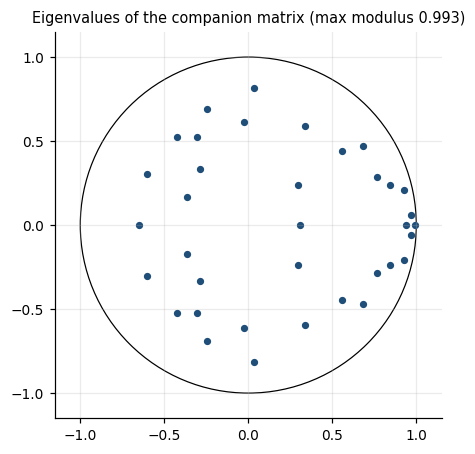

In [15]:
sel = VAR(data.values).select_order(8, trend="c")
print("Lag order chosen by each criterion (max 8):", sel.selected_orders)

wh = sm_res.test_whiteness(nlags=8)
print(f"Portmanteau test, H0: no residual autocorrelation up to lag 8: statistic {wh.test_statistic:.1f}, p-value {wh.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ev = np.linalg.eigvals(A)
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="k", lw=0.8))
ax.scatter(ev.real, ev.imag, s=14, color="#1f4e79")
ax.set_aspect("equal"); ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
ax.set_title(f"Eigenvalues of the companion matrix (max modulus {np.abs(ev).max():.3f})")
fig.tight_layout()
fig.savefig(FIG / "companion_roots.png", dpi=150, bbox_inches="tight")
plt.show()

All the companion eigenvalues are inside the unit circle, with the largest at about 0.99. This near-unit root is expected in a VAR in log levels: the responses of real activity die out within the 20-quarter window, while the price level is slow to settle (Sections 5 and 9).

The criteria disagree. BIC and HQ choose one lag, FPE two and AIC the maximum of eight; the paper's four lags sit in between. With four lags the portmanteau test still rejects the absence of residual autocorrelation up to lag 8. This has two consequences: the residual bootstrap, which resamples residuals as if they were independent, probably understates the uncertainty somewhat; and it is worth checking that the results do not hinge on $p = 4$. We re-estimate the VAR with 2 and 6 lags, keeping the same estimation sample.

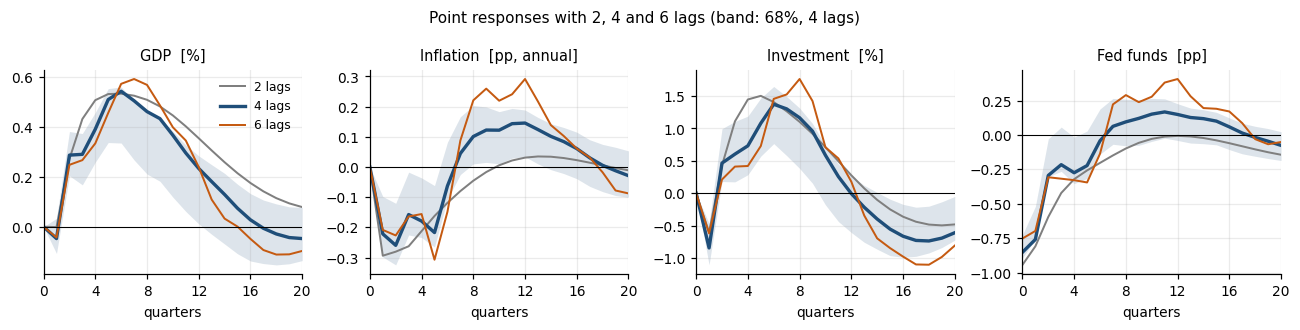

,2 lags,4 lags,6 lags
GDP peak (%),0.53,0.54,0.59
GDP peak quarter,6.00,6.00,7.00
investment peak (%),1.50,1.37,1.76
inflation trough (pp),-0.29,-0.26,-0.31
inflation peak (pp),0.04,0.15,0.29
inflation peak quarter,13.00,12.00,12.00
fed funds impact (pp),-0.94,-0.85,-0.75


In [16]:
LAGS = [2, 4, 6]
SHOW_L = [("GDP", "%"), ("Inflation", "pp, annual"), ("Investment", "%"), ("Fed funds", "pp")]
colors = {2: "#7f7f7f", 4: "#1f4e79", 6: "#c55a11"}

point_by_lag = {}
for p_ in LAGS:
    Y_p = df.loc[start - p_:end].values                    # same sample, p_ pre-sample quarters
    B_p, _, O_p = estimate_var(Y_p, p_)
    point_by_lag[p_] = -irf(B_p, O_p, p_, H, MP)

fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharex=True)
for ax, (v, unit) in zip(axes, SHOW_L):
    for p_ in LAGS:
        pt = point_by_lag[p_]
        y = infl(pt[D]) if v == "Inflation" else pt[VARS.index(v)]
        ax.plot(q_, y, color=colors[p_], lw=2.2 if p_ == P else 1.3, label=f"{p_} lags")
    if v != "Inflation":
        k = VARS.index(v)
        ax.fill_between(q_, lo68[k], hi68[k], color=colors[P], alpha=0.15, lw=0)
    else:
        ax.fill_between(q_, ilo68, ihi68, color=colors[P], alpha=0.15, lw=0)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_title(f"{v}  [{unit}]"); ax.set_xlim(0, H); ax.set_xticks(range(0, H + 1, 4))
    ax.set_xlabel("quarters")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Point responses with 2, 4 and 6 lags (band: 68%, 4 lags)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "robustness_lags.png", dpi=150, bbox_inches="tight")
plt.show()

rows = {}
for p_ in LAGS:
    pt = point_by_lag[p_]
    g, i_ = pt[VARS.index("GDP")], infl(pt[D])
    rows[f"{p_} lags"] = {
        "GDP peak (%)": g.max(), "GDP peak quarter": int(g.argmax()),
        "investment peak (%)": pt[VARS.index("Investment")].max(),
        "inflation trough (pp)": i_[:7].min(), "inflation peak (pp)": i_.max(),
        "inflation peak quarter": int(i_.argmax()), "fed funds impact (pp)": pt[MP, 0],
    }
pd.DataFrame(rows).round(2) + 0.0

The main results do not hinge on four lags:

- **Real activity.** GDP peaks at +0.53% to +0.59% after six or seven quarters with any of the three lag lengths, and investment keeps its hump. With 2 lags the responses are smoother and more persistent; with 6 the hump is sharper.
- **The policy shock.** The funds-rate cut on impact ranges from 75 to 94 basis points; with 2 lags it returns to baseline more slowly and does not overshoot.
- **Inflation.** The early dip is there with every lag length (−0.26 to −0.31 points), so the price puzzle is not an artefact of $p = 4$. The later rise is the most fragile result: with 2 lags inflation barely turns positive (+0.04 points), while with 6 it peaks at +0.29, above CEE's +0.2. The delayed rise of inflation is identified mostly by the longer lags, which is another reason to read it alongside the commodity-price specification of Section 9.